In [1]:
import math
import os
import sys
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")
from src.apriori import run_apriori
from src.fpgrowth import run_fpgrowth
from src.transactions import load_transactions

USE_SAMPLE = False

if USE_SAMPLE:
    TX_PATH = "../data/sample/tx_author_based_sample.pkl"
    SUFFIX = "_sample"
else:
    TX_PATH = "../data/processed/tx_author_based.pkl"
    SUFFIX = ""

FIGURES_DIR = "../figures"
STATS_OUT_DIR = "../data/results"
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(STATS_OUT_DIR, exist_ok=True)

MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]

transactions = load_transactions(TX_PATH)
N = len(transactions)
print(f"Transaksi: {TX_PATH}")
print(f"Jumlah transaksi: {N:,}")

Transaksi: ../data/processed/tx_author_based.pkl
Jumlah transaksi: 1,821,757


In [2]:
# jalankan apriori dan fp-growth di tiap min support, catat runtime
results = {}
runtimes = []

for ms in MIN_SUPPORTS:
    t0 = time.perf_counter()
    ap = run_apriori(transactions, ms)
    t_ap = time.perf_counter() - t0

    t0 = time.perf_counter()
    fp = run_fpgrowth(transactions, ms)
    t_fp = time.perf_counter() - t0

    assert ap == fp, f"Hasil Apriori dan FP-Growth berbeda pada min_support={ms}"
    results[ms] = ap
    runtimes.append({"min_support": ms, "apriori_s": round(t_ap, 3), "fpgrowth_s": round(t_fp, 3)})
    print(f"min_support={ms:<6} | itemset={len(ap):>6,} | apriori={t_ap:7.2f}s | fp-growth={t_fp:7.2f}s | identik")

min_support=0.001  | itemset= 1,514 | apriori=   9.35s | fp-growth=  10.08s | identik


min_support=0.005  | itemset=    88 | apriori=   2.32s | fp-growth=   3.33s | identik


min_support=0.01   | itemset=    30 | apriori=   1.94s | fp-growth=   3.71s | identik


min_support=0.02   | itemset=     6 | apriori=   1.70s | fp-growth=   2.12s | identik


In [3]:
# ubah dict{frozenset: support_count} jadi tabel dengan support dalam persen
def itemsets_to_df(itemsets: dict, n: int) -> pd.DataFrame:
    df = pd.DataFrame({
        "itemset": [", ".join(sorted(s)) for s in itemsets],
        "k": [len(s) for s in itemsets],
        "support_count": list(itemsets.values()),
    })
    df["support (%)"] = (df["support_count"] / n * 100).round(3)
    return df.sort_values(["support_count", "itemset"], ascending=[False, True]).reset_index(drop=True)

itemset_dfs = {ms: itemsets_to_df(res, N) for ms, res in results.items()}

# simpan seluruh frequent itemset per min support
for ms, df_ms in itemset_dfs.items():
    df_ms.to_csv(f"{STATS_OUT_DIR}/task4_itemsets_minsup_{ms}{SUFFIX}.csv", index=False)

In [4]:
# jumlah frequent itemset per ukuran k untuk tiap min support
count_rows = []
for ms, df_ms in itemset_dfs.items():
    by_k = df_ms["k"].value_counts()
    count_rows.append({
        "min_support": ms,
        "min_support_count": math.ceil(ms * N),
        "1-itemset": int(by_k.get(1, 0)),
        "2-itemset": int(by_k.get(2, 0)),
        "3-itemset": int(by_k.get(3, 0)),
        ">=4-itemset": int(by_k[by_k.index >= 4].sum()),
        "total": len(df_ms),
    })

# gabungkan dengan runtime kedua algoritma
summary = pd.DataFrame(count_rows).merge(pd.DataFrame(runtimes), on="min_support")
summary.to_csv(f"{STATS_OUT_DIR}/task4_summary{SUFFIX}.csv", index=False)
summary

,min_support,min_support_count,1-itemset,2-itemset,3-itemset,>=4-itemset,total,apriori_s,fpgrowth_s
0,0.001,1822,574,393,348,199,1514,9.355,10.076
1,0.005,9109,66,21,1,0,88,2.324,3.333
2,0.010,18218,29,1,0,0,30,1.936,3.713
3,0.020,36436,6,0,0,0,6,1.697,2.121


In [5]:
# frequent 1-, 2-, 3-itemset diambil dari min support terkecil (paling lengkap)
LOWEST = min(MIN_SUPPORTS)
base = itemset_dfs[LOWEST]

for k in [1, 2, 3]:
    print(f"Frequent {k}-itemset (min_support={LOWEST}), top 10 dari {int((base['k'] == k).sum()):,}:")
    display(base[base["k"] == k].head(10).reset_index(drop=True))

Frequent 1-itemset (min_support=0.001), top 10 dari 574:


,itemset,k,support_count,support (%)
0,nips,1,57800,3.173
1,cvpr,1,47664,2.616
2,aaai,1,46437,2.549
3,icassp,1,42057,2.309
4,embc,1,39318,2.158
5,hci,1,37884,2.080
6,igarss,1,35229,1.934
7,emnlp,1,33954,1.864
8,icml,1,31896,1.751
9,iros,1,31249,1.715


Frequent 2-itemset (min_support=0.001), top 10 dari 393:


,itemset,k,support_count,support (%)
0,"icml, nips",2,18503,1.016
1,"iclr, nips",2,17852,0.980
2,"aaai, nips",2,15973,0.877
3,"cvpr, nips",2,15640,0.859
4,"cvpr, iccv",2,15441,0.848
5,"acl, emnlp",2,14557,0.799
6,"cvpr, eccv",2,13752,0.755
7,"iclr, icml",2,12947,0.711
8,"aaai, cvpr",2,12169,0.668
9,"icra, iros",2,11860,0.651


Frequent 3-itemset (min_support=0.001), top 10 dari 348:


,itemset,k,support_count,support (%)
0,"iclr, icml, nips",3,10413,0.572
1,"cvpr, eccv, iccv",3,8474,0.465
2,"cvpr, iccv, nips",3,8407,0.461
3,"aaai, icml, nips",3,7585,0.416
4,"aaai, iclr, nips",3,7371,0.405
5,"aaai, cvpr, nips",3,7301,0.401
6,"cvpr, eccv, nips",3,7272,0.399
7,"cvpr, iclr, nips",3,7157,0.393
8,"aaai, cvpr, iccv",3,6477,0.356
9,"cvpr, icml, nips",3,6259,0.344


In [6]:
# top 10 itemset berdasarkan support (semua ukuran)
top10_all = base.head(10)
# top 10 kombinasi venue yang sering muncul bersama (k >= 2)
top10_multi = base[base["k"] >= 2].head(10).reset_index(drop=True)

top10_all.to_csv(f"{STATS_OUT_DIR}/task4_top10_itemsets{SUFFIX}.csv", index=False)
top10_multi.to_csv(f"{STATS_OUT_DIR}/task4_top10_venue_combinations{SUFFIX}.csv", index=False)

print("Top-10 itemset (semua ukuran):")
display(top10_all)
print("Top-10 kombinasi venue (k >= 2):")
display(top10_multi)

Top-10 itemset (semua ukuran):


,itemset,k,support_count,support (%)
0,nips,1,57800,3.173
1,cvpr,1,47664,2.616
2,aaai,1,46437,2.549
3,icassp,1,42057,2.309
4,embc,1,39318,2.158
5,hci,1,37884,2.080
6,igarss,1,35229,1.934
7,emnlp,1,33954,1.864
8,icml,1,31896,1.751
9,iros,1,31249,1.715


Top-10 kombinasi venue (k >= 2):


,itemset,k,support_count,support (%)
0,"icml, nips",2,18503,1.016
1,"iclr, nips",2,17852,0.980
2,"aaai, nips",2,15973,0.877
3,"cvpr, nips",2,15640,0.859
4,"cvpr, iccv",2,15441,0.848
5,"acl, emnlp",2,14557,0.799
6,"cvpr, eccv",2,13752,0.755
7,"iclr, icml",2,12947,0.711
8,"aaai, cvpr",2,12169,0.668
9,"icra, iros",2,11860,0.651


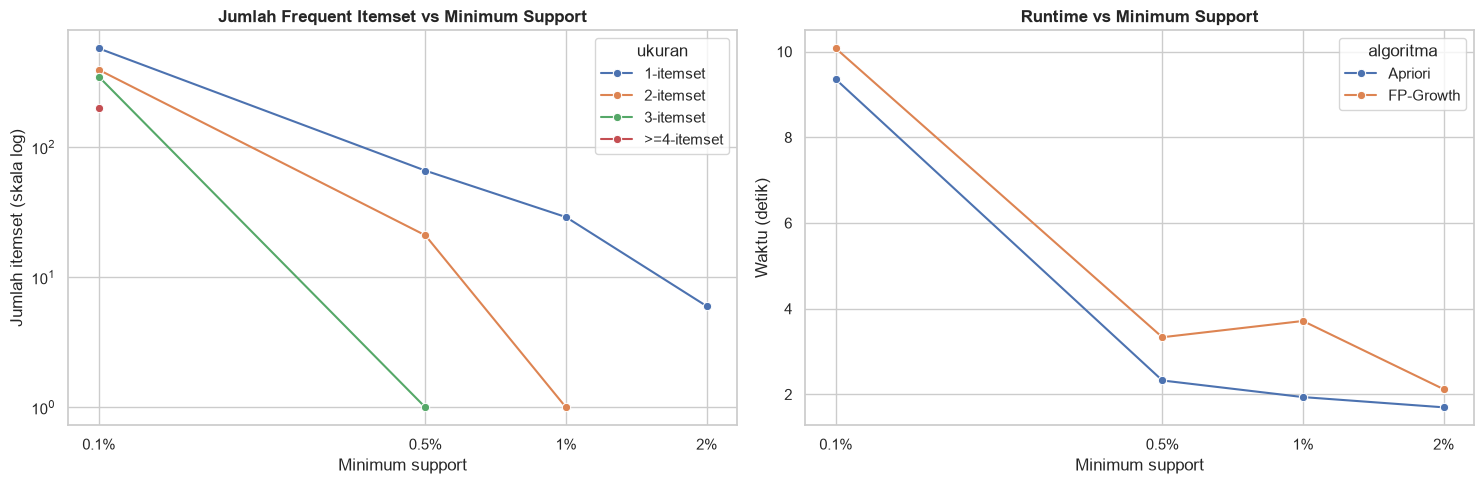

In [7]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# plot 1: pengaruh min support terhadap jumlah frequent itemset
plot_counts = summary.melt(
    id_vars="min_support",
    value_vars=["1-itemset", "2-itemset", "3-itemset", ">=4-itemset"],
    var_name="ukuran", value_name="jumlah",
)
plot_counts = plot_counts[plot_counts["jumlah"] > 0]
sns.lineplot(data=plot_counts, x="min_support", y="jumlah", hue="ukuran", marker="o", ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xticks(MIN_SUPPORTS)
axes[0].set_xticklabels([f"{ms * 100:g}%" for ms in MIN_SUPPORTS])
axes[0].set_title("Jumlah Frequent Itemset vs Minimum Support", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Minimum support")
axes[0].set_ylabel("Jumlah itemset (skala log)")

# plot 2: pengaruh min support terhadap runtime apriori vs fp-growth
rt = summary.melt(id_vars="min_support", value_vars=["apriori_s", "fpgrowth_s"], var_name="algoritma", value_name="detik")
rt["algoritma"] = rt["algoritma"].map({"apriori_s": "Apriori", "fpgrowth_s": "FP-Growth"})
sns.lineplot(data=rt, x="min_support", y="detik", hue="algoritma", marker="o", ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_xticks(MIN_SUPPORTS)
axes[1].set_xticklabels([f"{ms * 100:g}%" for ms in MIN_SUPPORTS])
axes[1].set_title("Runtime vs Minimum Support", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Minimum support")
axes[1].set_ylabel("Waktu (detik)")

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task4_minsup_effect{SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()

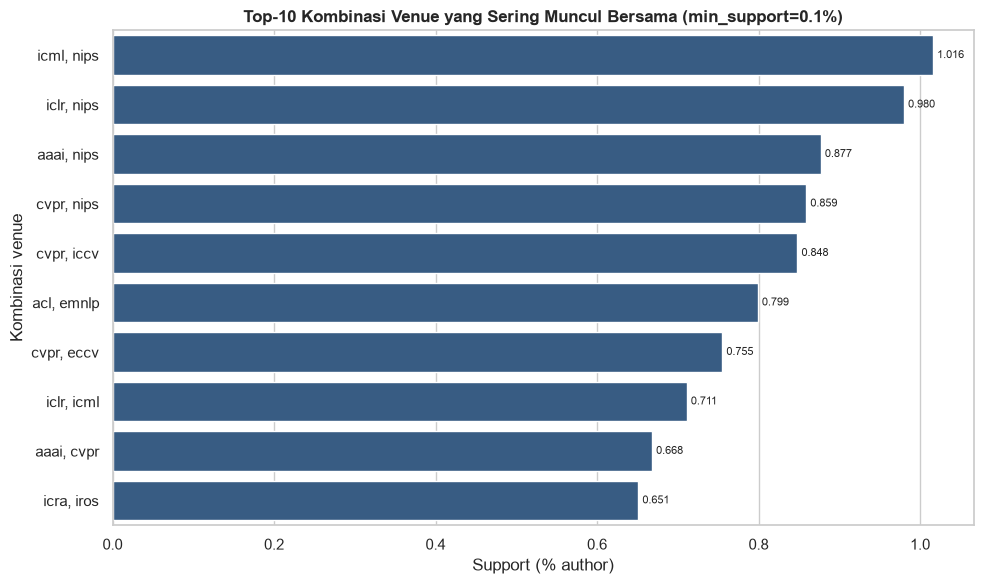

In [8]:
# plot top 10 kombinasi venue berdasarkan support
if len(top10_multi) > 0:
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=top10_multi, y="itemset", x="support (%)", color="#2b5c8f", ax=ax)
    ax.set_title(f"Top-10 Kombinasi Venue yang Sering Muncul Bersama (min_support={LOWEST * 100:g}%)", fontsize=12, fontweight="bold")
    ax.set_xlabel("Support (% author)")
    ax.set_ylabel("Kombinasi venue")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, padding=3)
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/task4_top10_venue_combinations{SUFFIX}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [9]:
from src.association_rules import generate_rules

# load author-year db untuk dibandingkan dengan author-based (pertanyaan kesimpulan no. 5)
AY_TX_PATH = TX_PATH.replace("tx_author_based", "tx_author_year_based")
ay_transactions = load_transactions(AY_TX_PATH)
N_AY = len(ay_transactions)
print(f"Jumlah transaksi Author-Based      : {N:,}")
print(f"Jumlah transaksi Author-Year-Based : {N_AY:,}")

# mining author-year di min support yang sama, cukup apriori karena hasilnya sudah terbukti identik dengan fp-growth
ay_results = {ms: run_apriori(ay_transactions, ms) for ms in MIN_SUPPORTS}
ay_itemset_dfs = {ms: itemsets_to_df(res, N_AY) for ms, res in ay_results.items()}

# jumlah frequent itemset per ukuran k untuk kedua representasi
db_rows = []
for name, dfs, n_tx in [("Author-Based", itemset_dfs, N), ("Author-Year-Based", ay_itemset_dfs, N_AY)]:
    for ms, df_ms in dfs.items():
        by_k = df_ms["k"].value_counts()
        db_rows.append({
            "representasi": name,
            "min_support": ms,
            "min_support_count": math.ceil(ms * n_tx),
            "1-itemset": int(by_k.get(1, 0)),
            "2-itemset": int(by_k.get(2, 0)),
            "3-itemset": int(by_k.get(3, 0)),
            ">=4-itemset": int(by_k[by_k.index >= 4].sum()),
            "total": len(df_ms),
            "k_maks": int(df_ms["k"].max()),
        })

db_counts = pd.DataFrame(db_rows).sort_values(["min_support", "representasi"]).reset_index(drop=True)
db_counts.to_csv(f"{STATS_OUT_DIR}/task4_ab_vs_ay_counts{SUFFIX}.csv", index=False)
db_counts

Jumlah transaksi Author-Based      : 1,821,757
Jumlah transaksi Author-Year-Based : 4,085,594


,representasi,min_support,min_support_count,1-itemset,2-itemset,3-itemset,>=4-itemset,total,k_maks
0,Author-Based,0.001,1822,574,393,348,199,1514,6
1,Author-Year-Based,0.001,4086,298,46,3,0,347,3
2,Author-Based,0.005,9109,66,21,1,0,88,3
3,Author-Year-Based,0.005,20428,42,0,0,0,42,1
4,Author-Based,0.010,18218,29,1,0,0,30,2
5,Author-Year-Based,0.010,40856,17,0,0,0,17,1
6,Author-Based,0.020,36436,6,0,0,0,6,1
7,Author-Year-Based,0.020,81712,2,0,0,0,2,1


In [10]:
# top 10 kombinasi venue (k >= 2) di tiap representasi, beserta peringkat dan support di representasi lain
ab_multi = itemset_dfs[LOWEST].query("k >= 2").reset_index(drop=True)
ay_multi = ay_itemset_dfs[LOWEST].query("k >= 2").reset_index(drop=True)
ab_multi["rank"] = ab_multi.index + 1
ay_multi["rank"] = ay_multi.index + 1

def top10_with_other(src, other, src_name, other_name):
    top = src.head(10)[["rank", "itemset", "support (%)"]]
    merged = top.merge(other[["itemset", "rank", "support (%)"]], on="itemset", how="left", suffixes=("", " other"))
    return merged.rename(columns={
        "rank": f"rank {src_name}",
        "support (%)": f"support {src_name} (%)",
        "rank other": f"rank {other_name}",
        "support (%) other": f"support {other_name} (%)",
    })

top10_ab_vs_ay = top10_with_other(ab_multi, ay_multi, "AB", "AY")
top10_ay_vs_ab = top10_with_other(ay_multi, ab_multi, "AY", "AB")
top10_ab_vs_ay.to_csv(f"{STATS_OUT_DIR}/task4_top10_ab_vs_ay{SUFFIX}.csv", index=False)
top10_ay_vs_ab.to_csv(f"{STATS_OUT_DIR}/task4_top10_ay_vs_ab{SUFFIX}.csv", index=False)

print(f"Top-10 kombinasi venue Author-Based (min_support={LOWEST * 100:g}%):")
display(top10_ab_vs_ay)
print(f"Top-10 kombinasi venue Author-Year-Based (min_support={LOWEST * 100:g}%):")
display(top10_ay_vs_ab)

# cek apakah pola author-year juga muncul di author-based
shared = set(ab_multi["itemset"]) & set(ay_multi["itemset"])
print(f"Kombinasi venue (k >= 2) Author-Based     : {len(ab_multi):,}")
print(f"Kombinasi venue (k >= 2) Author-Year-Based: {len(ay_multi):,}")
print(f"Muncul di keduanya                        : {len(shared):,}")
print(f"Hanya di Author-Year-Based                : {len(set(ay_multi['itemset']) - set(ab_multi['itemset'])):,}")

Top-10 kombinasi venue Author-Based (min_support=0.1%):


,rank AB,itemset,support AB (%),rank AY,support AY (%)
0,1,"icml, nips",1.016,1,0.434
1,2,"iclr, nips",0.980,2,0.402
2,3,"aaai, nips",0.877,6,0.301
3,4,"cvpr, nips",0.859,4,0.355
4,5,"cvpr, iccv",0.848,5,0.303
5,6,"acl, emnlp",0.799,3,0.373
6,7,"cvpr, eccv",0.755,9,0.244
7,8,"iclr, icml",0.711,7,0.272
8,9,"aaai, cvpr",0.668,10,0.244
9,10,"icra, iros",0.651,11,0.233


Top-10 kombinasi venue Author-Year-Based (min_support=0.1%):


,rank AY,itemset,support AY (%),rank AB,support AB (%)
0,1,"icml, nips",0.434,1,1.016
1,2,"iclr, nips",0.402,2,0.980
2,3,"acl, emnlp",0.373,6,0.799
3,4,"cvpr, nips",0.355,4,0.859
4,5,"cvpr, iccv",0.303,5,0.848
5,6,"aaai, nips",0.301,3,0.877
6,7,"iclr, icml",0.272,8,0.711
7,8,"globecom, icc",0.272,11,0.627
8,9,"cvpr, eccv",0.244,7,0.755
9,10,"aaai, cvpr",0.244,9,0.668


Kombinasi venue (k >= 2) Author-Based     : 940
Kombinasi venue (k >= 2) Author-Year-Based: 49
Muncul di keduanya                        : 49
Hanya di Author-Year-Based                : 0


In [11]:
# association rules dari kedua representasi dengan min confidence 50% (sama dengan task 5)
MIN_CONFIDENCE = 0.5

def format_rules(rules: pd.DataFrame) -> pd.DataFrame:
    out = rules.copy()
    out["antecedents"] = out["antecedents"].map(lambda s: ", ".join(sorted(s)))
    out["consequents"] = out["consequents"].map(lambda s: ", ".join(sorted(s)))
    return out.round({"support": 5, "confidence": 3, "lift": 2})

ab_rules = format_rules(generate_rules(results[LOWEST], N, MIN_CONFIDENCE))
ay_rules = format_rules(generate_rules(ay_results[LOWEST], N_AY, MIN_CONFIDENCE))
ab_rules.to_csv(f"{STATS_OUT_DIR}/task4_rules_author_based{SUFFIX}.csv", index=False)
ay_rules.to_csv(f"{STATS_OUT_DIR}/task4_rules_author_year{SUFFIX}.csv", index=False)

print(f"Jumlah rules Author-Based      : {len(ab_rules):,}")
print(f"Jumlah rules Author-Year-Based : {len(ay_rules):,}")

# rules author-year beserta nilai rule yang sama di author-based
ay_rules_vs_ab = ay_rules.merge(
    ab_rules, on=["antecedents", "consequents"], how="left", suffixes=(" AY", " AB")
)
print("Rules Author-Year-Based dan nilainya di Author-Based:")
display(ay_rules_vs_ab)
print("Top-10 rules Author-Based berdasarkan lift:")
display(ab_rules.head(10))

Jumlah rules Author-Based      : 1,387
Jumlah rules Author-Year-Based : 3
Rules Author-Year-Based dan nilainya di Author-Based:


,antecedents,consequents,support AY,confidence AY,lift AY,support AB,confidence AB,lift AB
0,"iccv, nips",cvpr,0.00101,0.561,27.12,0.00461,0.766,29.27
1,"iclr, icml",nips,0.00164,0.602,25.67,0.00572,0.804,25.35
2,"cvpr, iclr",nips,0.00104,0.555,23.70,0.00393,0.749,23.61


Top-10 rules Author-Based berdasarkan lift:


,antecedents,consequents,support,confidence,lift
0,"eccv, mm, nips","aaai, cvpr, iccv",0.00100,0.612,172.27
1,"cvpr, eccv, icml","iccv, iclr, nips",0.00101,0.502,171.81
2,"cvpr, iccv, icml, nips","eccv, iclr",0.00101,0.514,159.38
3,"cvpr, eccv, icml, nips","iccv, iclr",0.00101,0.591,157.30
4,"eccv, iccv, icml","cvpr, iclr, nips",0.00101,0.614,156.21
5,"iclr, naacl","acl, emnlp, nips",0.00105,0.504,152.46
6,"cvpr, iccv, mm, nips","aaai, eccv",0.00100,0.575,147.66
7,"emnlp, naacl, nips","acl, iclr",0.00105,0.546,146.26
8,"cvpr, eccv, mm, nips","aaai, iccv",0.00100,0.685,145.44
9,"cvpr, eccv, icml","iccv, iclr",0.00108,0.536,142.63


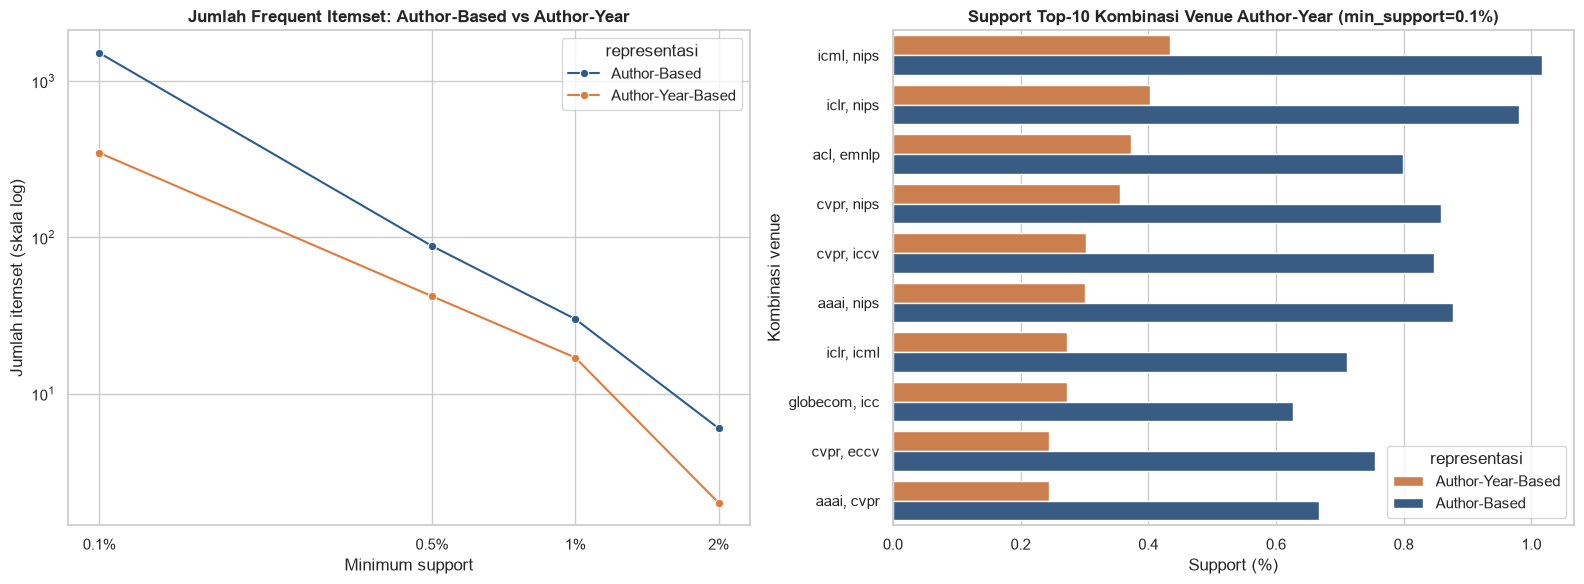

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# plot 1: jumlah frequent itemset kedua representasi per min support
sns.lineplot(data=db_counts, x="min_support", y="total", hue="representasi", marker="o",
             palette={"Author-Based": "#2b5c8f", "Author-Year-Based": "#e07b39"}, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xticks(MIN_SUPPORTS)
axes[0].set_xticklabels([f"{ms * 100:g}%" for ms in MIN_SUPPORTS])
axes[0].minorticks_off()
axes[0].set_title("Jumlah Frequent Itemset: Author-Based vs Author-Year", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Minimum support")
axes[0].set_ylabel("Jumlah itemset (skala log)")

# plot 2: support kombinasi venue top-10 author-year di kedua representasi
plot_top = top10_ay_vs_ab.melt(
    id_vars="itemset", value_vars=["support AY (%)", "support AB (%)"],
    var_name="representasi", value_name="support (%)",
)
plot_top["representasi"] = plot_top["representasi"].map({"support AY (%)": "Author-Year-Based", "support AB (%)": "Author-Based"})
sns.barplot(data=plot_top, y="itemset", x="support (%)", hue="representasi",
            palette={"Author-Based": "#2b5c8f", "Author-Year-Based": "#e07b39"}, ax=axes[1])
axes[1].set_title(f"Support Top-10 Kombinasi Venue Author-Year (min_support={LOWEST * 100:g}%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Support (%)")
axes[1].set_ylabel("Kombinasi venue")

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task4_ab_vs_ay{SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()